This notebook is just a quick check of the evaluation output to show basic Truth/Reconstructed histograms of predicted quantities

In [2]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
import awkward as ak

eval_output = "/farm/home/tjhellst/link_to_work/parnassus-clas12/clasdis_filtered/clasdis_filtered_eval_19k.root"
data = uproot.open(eval_output)["evt_tree"]
print(data.keys())


['eventNumber', 'pflow', 'pflow.p', 'pflow.theta', 'pflow.phi', 'pflow.beta', 'pflow.vx', 'pflow.vy', 'pflow.vz', 'pflow.pdgId', 'pflow.ind', 'truth', 'truth.p', 'truth.theta', 'truth.phi', 'truth.beta', 'truth.vx', 'truth.vy', 'truth.vz', 'truth.pdgId', 'truth.ind']


In [3]:
# load data arrays
fast_sim = data["pflow"].array()
truth = data["truth"].array()

# apply the particle level mask with ind > 0 to remove buffer from the model output
fast_sim = fast_sim[fast_sim["ind"] > 0]
truth = truth[truth["ind"] > 0]

print("fast sim type:", fast_sim.type)
print("truth type:", truth.type)


fast sim type: 19493 * var * {p: float32, theta: float32, phi: float32, beta: float32, vx: float32, vy: float32, vz: float32, pdgId: float32, ind: float32}
truth type: 19493 * var * {p: float32, theta: float32, phi: float32, beta: float32, vx: float32, vy: float32, vz: float32, pdgId: float32, ind: float32}


In [10]:
#plot styling:
var_styles = {"p": {"bins": np.linspace(0, 10, 100), "xlabel": "p (GeV)"},
              "theta": {"bins": np.linspace(0.1,0.6,100), "xlabel": "theta (rad)"},
              "phi": {"bins": np.linspace(-3.14, 3.14, 100), "xlabel": "phi (rad)"},
              "vx": {"bins": np.linspace(-0.1, 0.1, 100), "xlabel": "vx (cm)"},
              "vy": {"bins": np.linspace(-0.1, 0.1, 100), "xlabel": "vy (cm)"},
              "vz": {"bins": np.linspace(-0.1, 0.1, 100), "xlabel": "vz (cm)"},
              "pdgId": {"bins": np.linspace(0,12,12) - 0.5, "xlabel": "pid"},
              "N": {"bins": np.linspace(0, 10, 11) - 0.5, "xlabel": "Multiplicity"},
              }

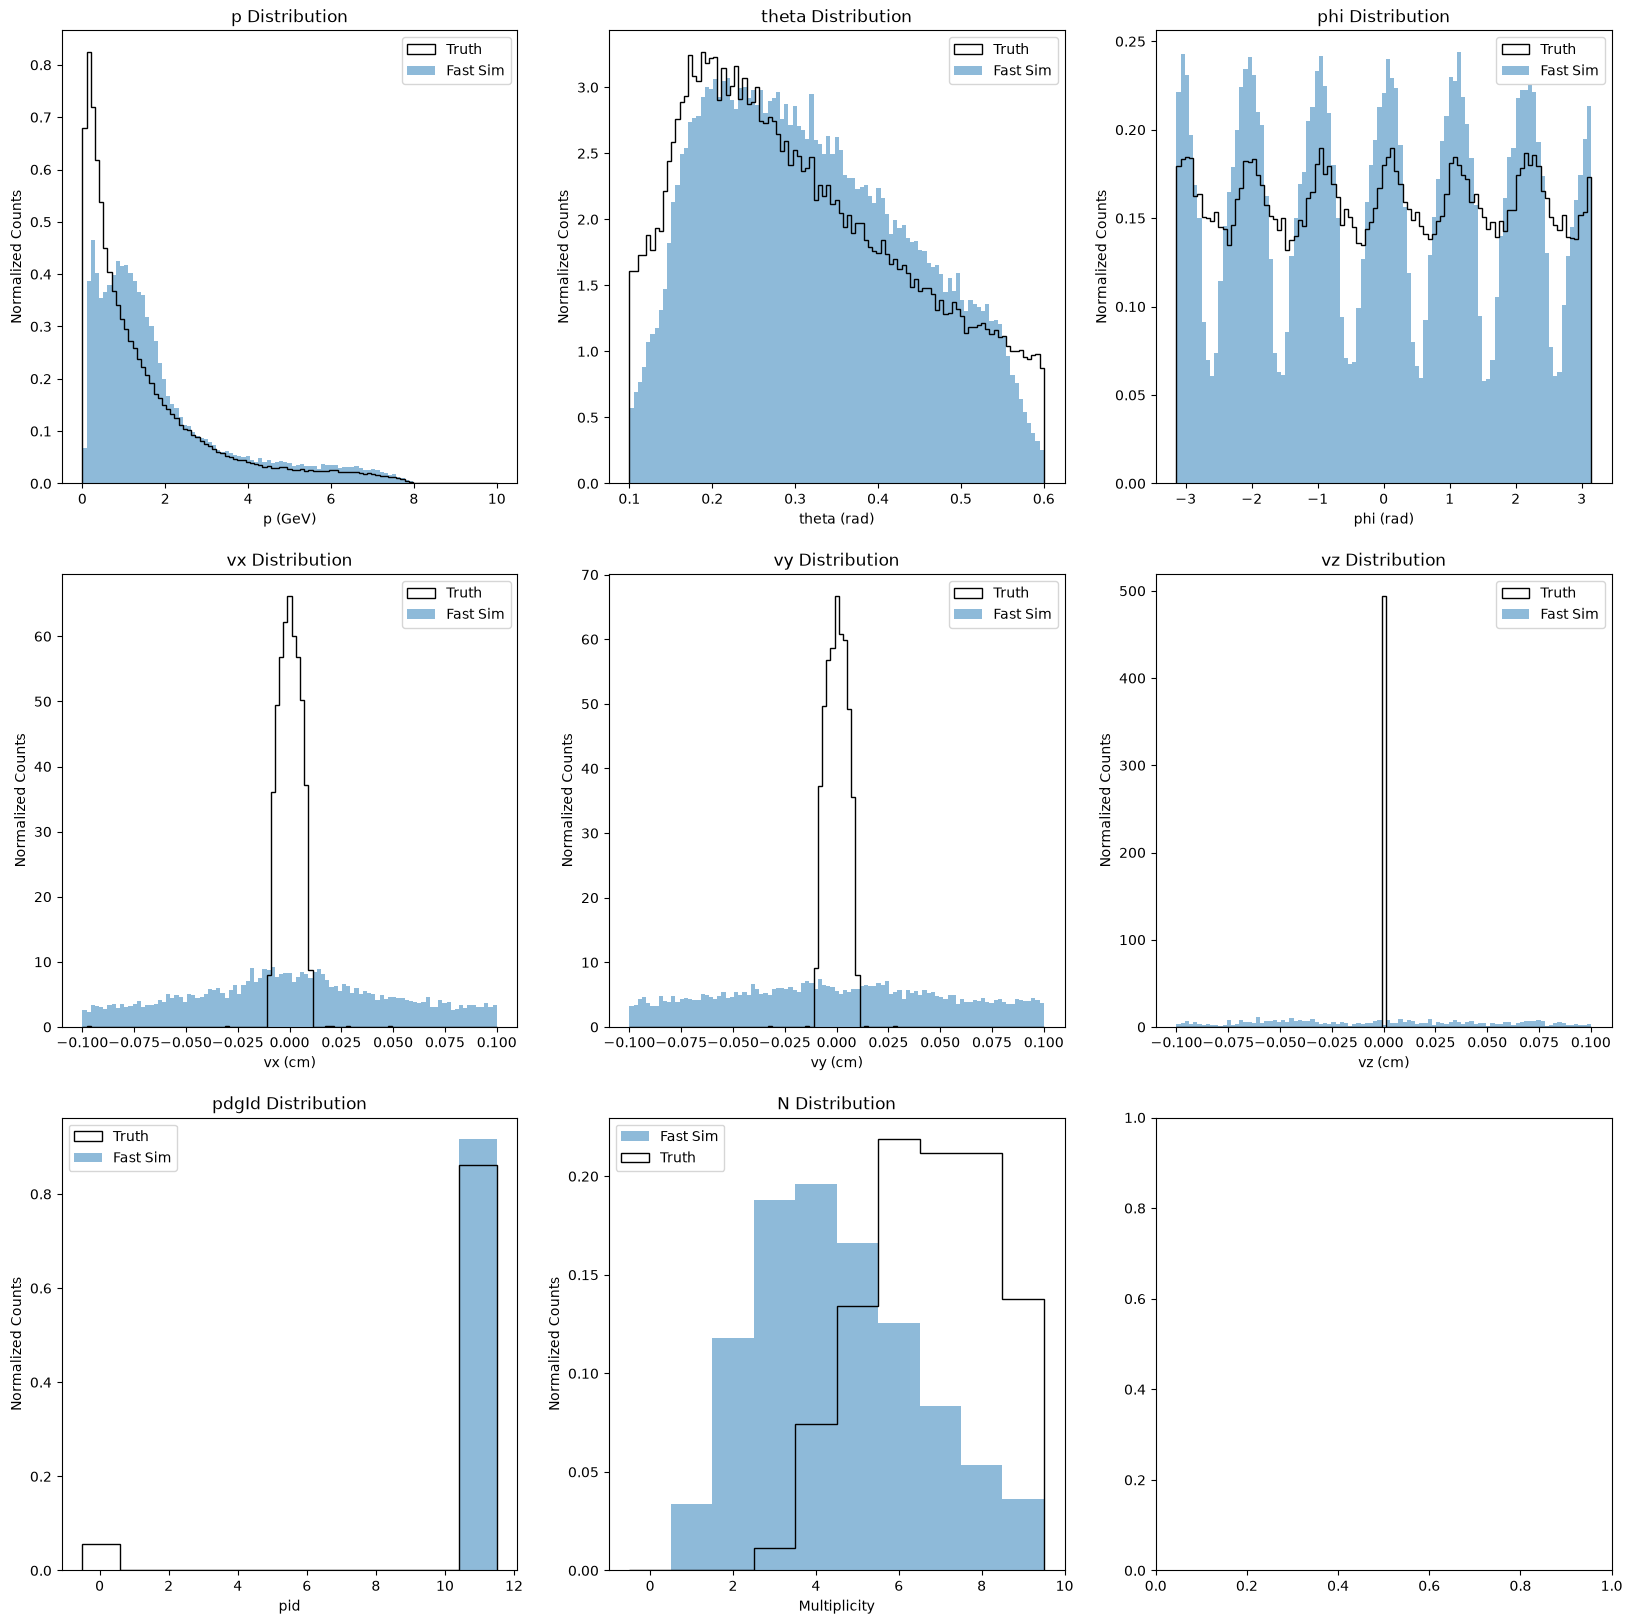

In [11]:
#plot the truth and fast sim distributions for comparison
def plot_histogram(fast_sim, truth, var, ax, density = True):
    if var == "N":
        # for multiplicity, we want to count the number of particles per event
        fast_sim_counts = ak.num(fast_sim)
        truth_counts = ak.num(truth)
        ax.hist(fast_sim_counts, bins=var_styles[var]["bins"], label="Fast Sim", color="#1f77b4", alpha=0.5,histtype="stepfilled", density=density)
        ax.hist(truth_counts, bins=var_styles[var]["bins"], label="Truth", color="black", histtype="step", density=density)
    else:
        ax.hist(ak.flatten(truth[var]), bins=var_styles[var]["bins"], label="Truth", color="black", histtype="step", density=density)
        ax.hist(ak.flatten(fast_sim[var]), bins=var_styles[var]["bins"], label="Fast Sim", color="#1f77b4", alpha=0.5,histtype="stepfilled", density=density)
    
    ax.set_xlabel(var_styles[var]["xlabel"])
    ylabel = "Normalized Counts" if density else "Counts"
    ax.set_ylabel(ylabel)
    ax.set_title(f"{var} Distribution")
    ax.legend()

fig, axs = plt.subplots(3,3, figsize=(20, 20))
axs_flat = axs.flatten()
for i, var in enumerate(var_styles.keys()):
    plot_histogram(fast_sim, truth, var, axs_flat[i])
